# code_154 · Mesh, boundary and conservation checks for reuse

**Book:** section29.5. Restart and run all cells in the pinned environment. All generated inputs, helpers and fitted teaching models are internal; no files, downloads, credentials or GPU are needed. Use the [quickstart](../README.md), [guide](../CHAPTER_29_GUIDE.md), [execution evidence](../CHAPTER_29_EXECUTION.md), [assets](../CHAPTER_29_ASSETS.md) and [registry](../CODE_EXAMPLES.md#code_154). Prerequisites: arrays, forecasting boundaries and Chapters24–26. Allow one minute for execution and30–60minutes to interpret the controls.

All task records are locally generated teaching inputs, not field observations. A generated series or equation family is not evidence of operational validity. Named forecasting checkpoints are identified explicitly; own shared forecasters and learned stencils are not Poseidon, Aurora, TimesFM or Chronos reproductions. Every fit, selected transformation, label budget and final assessment has a declared boundary. CPU float32 neural computations use one thread; numerical references use float64 where appropriate. The literature cutoff is18October2026; access21October2026 does not extend it.


In [1]:
import platform,time,json,copy,hashlib
import numpy as np,scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(3754);torch.use_deterministic_algorithms(True)
START=time.perf_counter();SEED=3754;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 3754


<a id="mesh-and-physics-validity"></a>
 ## Reuse a learned operator only with physical checks
 An original four-parameter stencil is fitted across128source diffusion cases on32periodic nodes, diffusivities0.01–0.04and smooth random initial fields. Its targets are exact one-step heat solutions with a deliberately disclosed+0.001observation calibration offset and small0.0001noise. Least squares fits three neighbouring field values and an intercept to the scaled update. This is a small reusable numerical surrogate, not a named scientific foundation model. On64/128new nodes and diffusivity0.06, compare raw reuse, a periodic-mean projection and an invalid old-grid scale. Rollouts use explicit diffusion number0.08and fixed physical duration0.1; all field errors are checked against analytic heat evolution. Native sparse matrix exponentiation on successively refined grids independently validates the reference. A separate fixed-endpoint Dirichlet problem tests a changed boundary family, including the invalid imposition of periodic mass conservation.


,grid,recipe,steps,RMSE,mean_error
0,64,Raw reuse,308,0.309712,0.309687
1,64,Periodic mean projection,308,0.003993,0.000000
2,64,Invalid old grid scale,308,0.093422,0.000000
3,128,Raw reuse,1229,1.271421,1.271234
4,128,Periodic mean projection,1229,0.021821,0.000000
5,128,Invalid old grid scale,1229,0.136735,0.000000


,recipe,RMSE,max_endpoint_error,mean_change
0,Periodic wrap reused,0.368529,0.651585,0.303955
1,Dirichlet endpoints,0.274096,0.000000,0.209962
2,Invalid conserved mean,0.055784,0.000000,0.000000


Reference refinement: [{'grid': 64, 'native_vs_analytic_RMSE': 0.0002674506214629621}, {'grid': 128, 'native_vs_analytic_RMSE': 6.66367384971822e-05}, {'grid': 256, 'native_vs_analytic_RMSE': 1.664506521630154e-05}]


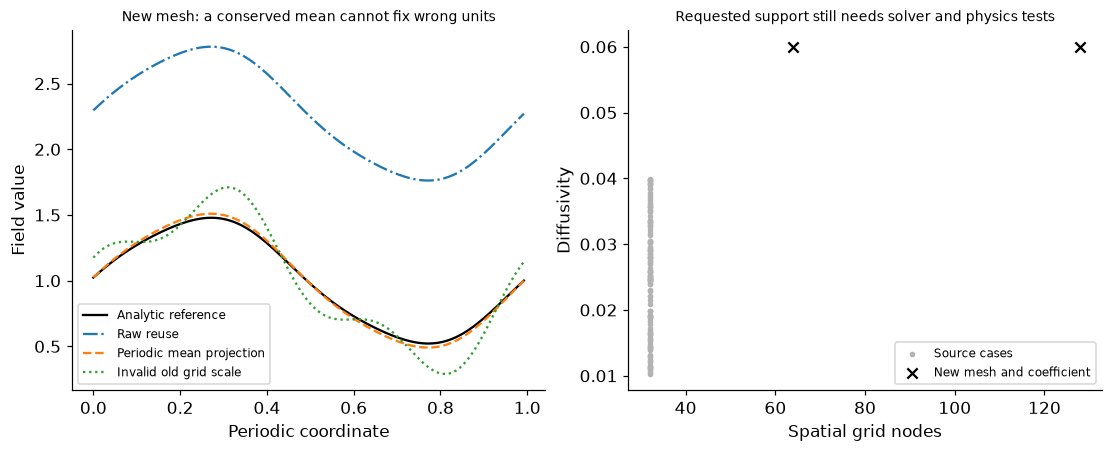

In [2]:
from sklearn.linear_model import LinearRegression
from scipy.sparse import diags,lil_matrix
from scipy.sparse.linalg import expm_multiply
n_source=32;h_source=1/n_source;design=[];targets=[];source_kappa=[]
def periodic_exact(u,kappa,duration):
    wave=2*np.pi*np.fft.rfftfreq(len(u),d=1/len(u));return np.fft.irfft(np.fft.rfft(u)*np.exp(-kappa*wave**2*duration),n=len(u))
for j in range(128):
    kappa=rng.uniform(.01,.04);source_kappa.append(kappa);x=np.arange(n_source)/n_source;u=np.full(n_source,rng.uniform(.5,1.5))
    for mode in range(1,5):u+=rng.normal(0,.4/mode)*np.sin(2*np.pi*mode*x+rng.uniform(0,2*np.pi))
    dt=.08*h_source**2/kappa;observed=periodic_exact(u,kappa,dt)+.001+rng.normal(0,.0001,n_source);design.append(np.stack([np.roll(u,1),u,np.roll(u,-1)],1));targets.append((observed-u)/.08)
fit=LinearRegression().fit(np.concatenate(design),np.concatenate(targets));weights=fit.coef_.copy();bias=float(fit.intercept_);assert weights.shape==(3,)
def roll_periodic(u,kappa,duration,project=False,wrong_grid=False):
    n=len(u);h=1/n;steps=int(np.ceil(duration*kappa/(.08*h*h)));dt=duration/steps;state=u.copy();mean=u.mean();ratio=kappa*dt/(h_source*h_source if wrong_grid else h*h)
    for _ in range(steps):
        update=weights[0]*np.roll(state,1)+weights[1]*state+weights[2]*np.roll(state,-1)+bias;state=state+ratio*update
        if project:state+=mean-state.mean()
    return state,steps
rows=[];curves={};T=.1;kappa=.06;reference_checks=[]
for n in [64,128,256]:
    x=np.arange(n)/n;u=1+.6*np.sin(2*np.pi*x)+.2*np.cos(6*np.pi*x);exact=periodic_exact(u,kappa,T);matrix=lil_matrix(diags([np.ones(n-1),-2*np.ones(n),np.ones(n-1)],[-1,0,1],shape=(n,n)));matrix[0,n-1]=matrix[n-1,0]=1;matrix=matrix.tocsr()*kappa*n*n;native=expm_multiply(T*matrix,u);reference_checks.append({'grid':n,'native_vs_analytic_RMSE':float(np.sqrt(np.mean((native-exact)**2)))})
    if n in [64,128]:
        for name,project,wrong in [('Raw reuse',False,False),('Periodic mean projection',True,False),('Invalid old grid scale',True,True)]:
            pred,steps=roll_periodic(u,kappa,T,project,wrong);curves[(n,name)]=pred;rows.append({'grid':n,'recipe':name,'steps':steps,'RMSE':float(np.sqrt(np.mean((pred-exact)**2))),'mean_error':float(abs(pred.mean()-u.mean()))})
assert reference_checks[2]['native_vs_analytic_RMSE']<reference_checks[1]['native_vs_analytic_RMSE']<reference_checks[0]['native_vs_analytic_RMSE']
for n in [64,128]:assert next(r['mean_error'] for r in rows if r['grid']==n and r['recipe']=='Periodic mean projection')<1e-12
# Changed boundary: the heat equation on [0,1] with fixed endpoint values zero.
n=64;x=np.linspace(0,1,n+1);u=np.sin(np.pi*x)+.2*np.sin(3*np.pi*x);reference=np.sin(np.pi*x)*np.exp(-kappa*np.pi**2*T)+.2*np.sin(3*np.pi*x)*np.exp(-kappa*(3*np.pi)**2*T);steps=int(np.ceil(T*kappa/(.08/n**2)));dt=T/steps;ratio=kappa*dt*n*n;boundary_rows=[];boundary_curves={}
for name in ['Periodic wrap reused','Dirichlet endpoints','Invalid conserved mean']:
    state=u.copy()
    for _ in range(steps):
        state+=ratio*(weights[0]*np.roll(state,1)+weights[1]*state+weights[2]*np.roll(state,-1)+bias)
        if name!='Periodic wrap reused':state[[0,-1]]=0
        if name=='Invalid conserved mean':state[1:-1]+=(u.sum()-state.sum())/(n-1)
    boundary_curves[name]=state;boundary_rows.append({'recipe':name,'RMSE':float(np.sqrt(np.mean((state-reference)**2))),'max_endpoint_error':float(np.max(np.abs(state[[0,-1]]))),'mean_change':float(state.mean()-u.mean())})
# Independent Dirichlet reference: sparse semidiscrete solve on 256 intervals.
nr=256;xr=np.linspace(0,1,nr+1);ur=np.sin(np.pi*xr)+.2*np.sin(3*np.pi*xr);lap=diags([np.ones(nr-2),-2*np.ones(nr-1),np.ones(nr-2)],[-1,0,1])*kappa*nr**2;native=expm_multiply(T*lap,ur[1:-1]);analytic=np.sin(np.pi*xr[1:-1])*np.exp(-kappa*np.pi**2*T)+.2*np.sin(3*np.pi*xr[1:-1])*np.exp(-kappa*(3*np.pi)**2*T);dirichlet_reference_RMSE=float(np.sqrt(np.mean((native-analytic)**2)));assert dirichlet_reference_RMSE<2e-5
assert next(r['max_endpoint_error'] for r in boundary_rows if r['recipe']=='Dirichlet endpoints')==0
RESULTS.update(source_cases=128,source_grid=32,source_diffusivity_range=[.01,.04],target_diffusivity=kappa,physical_duration=T,source_observation_bias=.001,source_observation_noise_sd=.0001,learned_stencil=weights.tolist(),learned_intercept=bias,learned_parameters=4,new_mesh_comparisons=rows,periodic_reference_refinement=reference_checks,boundary_comparisons=boundary_rows,dirichlet_reference_RMSE=dirichlet_reference_RMSE,named_scientific_checkpoint_executed=False);display(pd.DataFrame(rows));display(pd.DataFrame(boundary_rows));print('Reference refinement:',reference_checks)
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=np.arange(128)/128;initial=1+.6*np.sin(2*np.pi*xx)+.2*np.cos(6*np.pi*xx);axes[0].plot(xx,periodic_exact(initial,kappa,T),color='black',label='Analytic reference')
for name,style in [('Raw reuse','-.'),('Periodic mean projection','--'),('Invalid old grid scale',':')]:axes[0].plot(xx,curves[(128,name)],linestyle=style,label=name)
axes[0].set(xlabel='Periodic coordinate',ylabel='Field value',title='New mesh: a conserved mean cannot fix wrong units');axes[0].legend(fontsize=8);axes[1].scatter(np.full(128,32),source_kappa,s=7,c='.7',label='Source cases');axes[1].scatter([64,128],[kappa,kappa],c='black',marker='x',s=45,label='New mesh and coefficient');axes[1].set(xlabel='Spatial grid nodes',ylabel='Diffusivity',title='Requested support still needs solver and physics tests');axes[1].legend(fontsize=8);plt.show()


<a id="physical-acceptance-tests"></a>
 ## Conservation must match the boundary problem
 Periodic diffusion preserves the spatial mean, so projection removes one valid diagnostic failure while leaving field-shape error. Fixed zero Dirichlet endpoints instead allow heat to leave the domain; forcing the initial mean to persist contradicts that physics. A predictor can satisfy endpoint values exactly while retaining biased interior evolution. The unknown observation calibration offset remains part of the fitted surrogate even when a valid mean projection hides its effect in one task. Refinement compares the native sparse simulator to an independently computed analytic solution before using either as assessment evidence. More output nodes, new coordinate units and a changed boundary regime are distinct transfer questions. Stability over this short explicit rollout does not certify all elapsed times or coefficients.


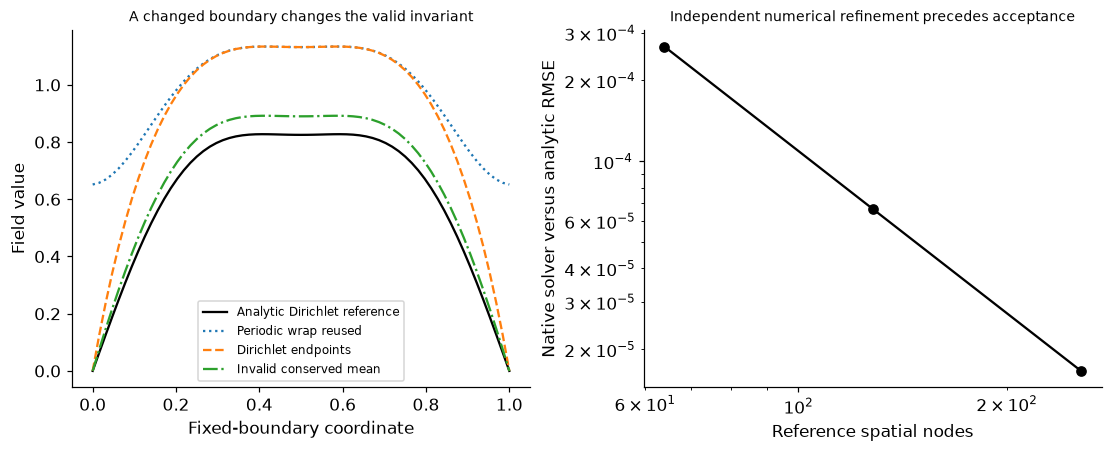

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(x,reference,color='black',label='Analytic Dirichlet reference')
for name,style in [('Periodic wrap reused',':'),('Dirichlet endpoints','--'),('Invalid conserved mean','-.')]:axes[0].plot(x,boundary_curves[name],linestyle=style,label=name)
axes[0].set(xlabel='Fixed-boundary coordinate',ylabel='Field value',title='A changed boundary changes the valid invariant');axes[0].legend(fontsize=8);axes[1].loglog([r['grid'] for r in reference_checks],[r['native_vs_analytic_RMSE'] for r in reference_checks],marker='o',color='black');axes[1].set(xlabel='Reference spatial nodes',ylabel='Native solver versus analytic RMSE',title='Independent numerical refinement precedes acceptance');plt.show()
assert len(rows)==6 and len(boundary_rows)==3 and np.isfinite(weights).all()


In [4]:
summary={'example_id':'code_154','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual shared learned diffusion stencil with disclosed observation bias', 'new-mesh physical scaling and deliberate wrong-grid fixture', 'independent converged sparse numerical references and analytic checks', 'periodic conservation projection versus invalid Dirichlet mass constraint', 'boundary values rollout stability and field errors checked separately'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual shared learned diffusion stencil with disclosed observation bias", "new-mesh physical scaling and deliberate wrong-grid fixture", "independent converged sparse numerical references and analytic checks", "periodic conservation projection versus invalid Dirichlet mass constraint", "boundary values rollout stability and field errors checked separately"], "elapsed_seconds": 0.55, "example_id": "code_154", "hardware": "Darwin arm64 CPU", "results": {"boundary_comparisons": [{"RMSE": 0.368528758186009, "max_endpoint_error": 0.6515852716998055, "mean_change": 0.3039554476756675, "recipe": "Periodic wrap reused"}, {"RMSE": 0.2740959144863247, "max_endpoint_error": 0.0, "mean_change": 0.20996183345334984, "recipe": "Dirichlet endpoints"}, {"RMSE": 0.055784093750348804, "max_endpoint_error": 0.0, "mean_change": 0.0, "recipe": "Invalid conserved mean"}], "dirichlet_reference_RMSE": 5.030320219844247e-06, "learned_intercept": 0.011796565825